In [1]:
import pandas as pd
import numpy as np 
from pathlib import Path

In [17]:
scheduled_df = pd.read_csv("/home/tp/mem-opt/results/processed/grouped_data.csv")
baseline_df = pd.read_csv("/home/tp/mem-opt/results/processed/baseline_data.csv")
    

In [18]:
scheduled_df.describe()

,llc_access,llc_misses,l2_refill,l2_read,l2_write
count,4.200000e+01,4.200000e+01,4.200000e+01,4.200000e+01,42.0
mean,4.178307e+07,6.511463e+06,9.614851e+06,9.614854e+06,0.0
std,4.078376e+07,1.744156e+07,4.028010e+06,4.028009e+06,0.0
min,1.599540e+07,1.637126e+06,5.270733e+06,5.270736e+06,0.0
25%,2.211740e+07,2.083367e+06,5.743114e+06,5.743118e+06,0.0
50%,3.202984e+07,3.176426e+06,9.428278e+06,9.428281e+06,0.0
75%,4.298679e+07,3.898277e+06,1.381296e+07,1.381296e+07,0.0
max,2.605338e+08,1.118950e+08,2.076367e+07,2.076368e+07,0.0


In [19]:
merge = scheduled_df.merge(baseline_df, on=["model", "layer"], suffixes=("","_baseline"))

In [21]:
merge.columns

Index(['timestamp', 'model', 'layer', 'schedule', 'llc_access', 'llc_misses',
       'l2_refill', 'l2_read', 'l2_write', 'timestamp_baseline',
       'schedule_baseline', 'llc_access_baseline', 'llc_misses_baseline',
       'l2_refill_baseline', 'l2_read_baseline', 'l2_write_baseline'],
      dtype='str')

In [22]:
merge.head(5)

,timestamp,model,layer,schedule,llc_access,llc_misses,l2_refill,l2_read,l2_write,timestamp_baseline,schedule_baseline,llc_access_baseline,llc_misses_baseline,l2_refill_baseline,l2_read_baseline,l2_write_baseline
0,2026-05-19T14:38:12,AlexNet,Alex_conv1,Row-stationary inspired,44760121,3909298,14430412,14430414,0,2026-05-19T14:38:11,baseline,60277748,5584010,21226070,21226073,0
1,2026-05-19T14:38:15,AlexNet,Alex_conv2,Row-stationary inspired,42801621,3865214,13872679,13872681,0,2026-05-19T14:38:14,baseline,16715849,1687877,5416078,5416081,0
2,2026-05-19T14:38:18,AlexNet,Alex_conv3,Row-stationary inspired,42857338,3805640,13823386,13823389,0,2026-05-19T14:38:17,baseline,17030851,1884726,5582988,5582992,0
3,2026-05-19T14:38:20,AlexNet,Alex_conv4,Row-stationary inspired,42769336,3785375,13777192,13777193,0,2026-05-19T14:38:19,baseline,16628504,1877651,5405283,5405288,0
4,2026-05-19T14:38:23,AlexNet,Alex_conv5,Row-stationary inspired,42321477,3647593,13642273,13642275,0,2026-05-19T14:38:22,baseline,16542220,1596466,5365902,5365906,0


In [23]:
normalized_df = merge.copy()
numeric_cols = scheduled_df.select_dtypes(include=["number"]).columns
for col in numeric_cols:
    baseline_col = f"{col}_baseline"
    if baseline_col in merge.columns:
        normalized_df[col] = normalized_df[col]/normalized_df[baseline_col]


In [24]:
normalized_df.head(5)

,timestamp,model,layer,schedule,llc_access,llc_misses,l2_refill,l2_read,l2_write,timestamp_baseline,schedule_baseline,llc_access_baseline,llc_misses_baseline,l2_refill_baseline,l2_read_baseline,l2_write_baseline
0,2026-05-19T14:38:12,AlexNet,Alex_conv1,Row-stationary inspired,0.742565,0.700088,0.679844,0.679844,NaN,2026-05-19T14:38:11,baseline,60277748,5584010,21226070,21226073,0
1,2026-05-19T14:38:15,AlexNet,Alex_conv2,Row-stationary inspired,2.560541,2.289986,2.561388,2.561387,NaN,2026-05-19T14:38:14,baseline,16715849,1687877,5416078,5416081,0
2,2026-05-19T14:38:18,AlexNet,Alex_conv3,Row-stationary inspired,2.516453,2.019201,2.475983,2.475982,NaN,2026-05-19T14:38:17,baseline,17030851,1884726,5582988,5582992,0
3,2026-05-19T14:38:20,AlexNet,Alex_conv4,Row-stationary inspired,2.572050,2.016016,2.548838,2.548836,NaN,2026-05-19T14:38:19,baseline,16628504,1877651,5405283,5405288,0
4,2026-05-19T14:38:23,AlexNet,Alex_conv5,Row-stationary inspired,2.558392,2.284792,2.542401,2.542399,NaN,2026-05-19T14:38:22,baseline,16542220,1596466,5365902,5365906,0


In [25]:
baseline_cols = [col for col in normalized_df.columns if col.endswith("_baseline")]
normalized_df.drop(columns = baseline_cols, inplace=True)

In [26]:
normalized_df.head(5)

,timestamp,model,layer,schedule,llc_access,llc_misses,l2_refill,l2_read,l2_write
0,2026-05-19T14:38:12,AlexNet,Alex_conv1,Row-stationary inspired,0.742565,0.700088,0.679844,0.679844,NaN
1,2026-05-19T14:38:15,AlexNet,Alex_conv2,Row-stationary inspired,2.560541,2.289986,2.561388,2.561387,NaN
2,2026-05-19T14:38:18,AlexNet,Alex_conv3,Row-stationary inspired,2.516453,2.019201,2.475983,2.475982,NaN
3,2026-05-19T14:38:20,AlexNet,Alex_conv4,Row-stationary inspired,2.572050,2.016016,2.548838,2.548836,NaN
4,2026-05-19T14:38:23,AlexNet,Alex_conv5,Row-stationary inspired,2.558392,2.284792,2.542401,2.542399,NaN


In [28]:
normalized_df.drop(columns=["timestamp"])

,model,layer,schedule,llc_access,llc_misses,l2_refill,l2_read,l2_write
0,AlexNet,Alex_conv1,Row-stationary inspired,0.742565,0.700088,0.679844,0.679844,NaN
1,AlexNet,Alex_conv2,Row-stationary inspired,2.560541,2.289986,2.561388,2.561387,NaN
2,AlexNet,Alex_conv3,Row-stationary inspired,2.516453,2.019201,2.475983,2.475982,NaN
3,AlexNet,Alex_conv4,Row-stationary inspired,2.572050,2.016016,2.548838,2.548836,NaN
4,AlexNet,Alex_conv5,Row-stationary inspired,2.558392,2.284792,2.542401,2.542399,NaN
5,AlexNet,Alex_conv1,output_stationary_inspired,0.473358,0.456922,0.469090,0.469090,NaN
6,AlexNet,Alex_conv2,output_stationary_inspired,1.592235,1.482931,1.745788,1.745787,NaN
7,AlexNet,Alex_conv3,output_stationary_inspired,1.590680,1.351782,1.690581,1.690580,NaN
8,AlexNet,Alex_conv4,output_stationary_inspired,1.628033,1.327337,1.748901,1.748900,NaN
9,AlexNet,Alex_conv5,output_stationary_inspired,1.634541,1.549420,1.755168,1.755168,NaN


In [29]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
width = 0.5
multiplier = 0

In [38]:
models = ["AlexNet", "VGG16", "MobileNet"]
schedules = ("Row-stationary inspired", "output_stationary_inspired", "weight_stationary_inspired")


In [42]:
normalized_df.columns

Index(['timestamp', 'model', 'layer', 'schedule', 'llc_access', 'llc_misses',
       'l2_refill', 'l2_read', 'l2_write'],
      dtype='str')

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

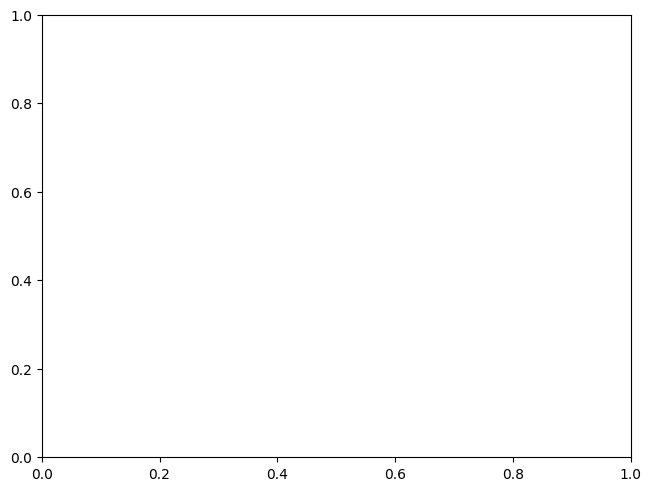

In [41]:
x = np.arange(len(schedules))
fig, ax = plt.subplots(layout='constrained')
for model in models:
    if normalized_df['model'] == model:
        for measurement in normalized_df['l2_refill']:
            offset = width * multiplier
            rects = ax.bar(x + offset, measurement, width, label='l2_refill')
            ax.bar_label(rects, padding=3)
            multiplier += 1

ax.set_ylabel('l2_refill')
ax.set_title('L2 level cache miss')
ax.set_xticks(x + width, schedules)
# ax.legend(loc='upper left', ncols=3)
ax.set_ylim(0,3)

plt.show()